**Exercise overview**
Explored how regularization and cross-validation reduce overfitting and improve generalization in regression models using polynomial features.

## Q12 - NN

## e + f
_Loss functions, Regularization, data augmentation, model complexity, cross-validation_
_Regularization, cross-validation and bias-variance_

**Signs of overfitting and underfitting**
- Overfitting:
	- **Variance:** Low loss on training data but high loss on validation/test sets.
	- Model learns noise and irrelevant patterns in the training data.
- Underfitting:
	- Poor accuracy on both training and validation/test sets.
	- **Bias:** Model is too simple or not trained long enough.
	- Solutions:
		- Increase model complexity (add layers/neurons).

**Tools to prevent overfitting:**

**Regularization**
- Using complex models may produce solutions that:
    - Overfit noisy data by trying to perfectly fit all points.
    - Have large coefficients
- Regularization imposes a penalty on large model parameters to improve generalization.
- $\text{Ridge: } \min_{\mathbf{w}} \ MSE+ \lambda ||\mathbf{w}||^2$
    - 	Small penalty : Slight regularization
	-	Large penalty : Strong regularization (risk of underfitting).

**Splits and cross-validation**
- Train-Test Splits:
    - Limitations: A single train-test split may result in high variance, depending on how the data is split.
- Cross-Validation
    - More robust assessment of generalization.
    - k-folds
	- Ensures all data points are used for both training and testing.
    - Detects high variance and overfitting

**Model complixity**
- Choose the simplest models that can capture the patterns of the data
- NN is not always a good choice for a simple model (e.g. linear)

# Bias-variance and regularization
This exercise is about applying regularization to mitigate the effects of overfitting. This exercise assumes that you have read the tutorial about cross validation
.

<article class="message">
    <div class="message-body">
        <strong>List of tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#reflect">Task 1: Tutorial review</a>
            </li>
            <li>
            <a href="#ridge0">Task 2: Reflections on regularization</a>
            </li>
            <li>
            <a href="#ridge1111">Task 3: Loading the dataset</a>
            </li>
            <li>
            <a href="#ride">Task 4: Implementing regularization</a>
            </li>
            <li>
            <a href="#eval">Task 5: Evaluating models</a>
            </li>
            <li>
            <a href="#cv">Task 6: Cross validation</a>
            </li>
            <li>
            <a href="#reflection">Task 7: Reflection on results</a>
            </li>
        </ul>
    </div>
</article>

## Reflection on the tutorial

---
**Task 1 (easy): Tutorial review👩‍💻💡**
1. Make a copy of the tutorial and make edits in the copy. 

2. In the tutorial, go to the "Hold-out validation" section and add a for loop that runs the cell for at least 10 iterations. That is, in each iteration:
    - Run the hold-out train-validation split. 
    - Fit the model on the training set. 
    - Compute and store the $R^2$ scores on the validation set.


3. Inspect the minimum and maximum $R^2$ scores and calculate their mean and variance. What does this indicate about the influence of the training set on model predictions?

4. Go to the "Effects of polynomials on model fit" section and implement 10 fold cross validation to train the models with 3rd, 4th, and 5th order polynomials. Does this affect the fit of the models? 



---

In [3]:
# Add your reflections here

## Regularization
In the cross validation tutorial
, it was observed that adding third or higher order polynomial terms results in overfitting of the regression model. In the following steps, a model pipeline similar to the one from the tutorial will be built, this time using ridge regression.

---
**Task 2 (easy): Reflections on regularization💡**
1. Define the loss function used in ridge regression.
2. What is the importance of the regularization parameter $\lambda$?
3. What influence does $\lambda$ have when it becomes:    - 0?
    - 1?
    - Large?




---

In [4]:
# 1: Loss function used in ridge regression
## A combination of ordinary least squares and a regularisation term that penalises large coefficients (the L2 norm of the coefficients).
## And a reularisation parameter that controls the strength of the penalty.

# 2: Importance of regularisation parameter (lambda) in ridge regression
## Bias-Variance Trade-off:
# A small λ allows the model to fit the data more closely, potentially leading to overfitting (low bias but high variance).
# A large λ reduces the magnitude of the coefficients, simplifying the model and reducing variance at the cost of higher bias.

# What influence does lambda have 
## When it is 0
### The model becomes equivalent to ordinary least squares regression (no regularization).
## When it is 1 
### A moderate penalty is applied, balancing the fit to the training data and the size of the coefficients.
## When it is very large
### The penalty on the coefficients dominates the loss function.
### The regression coefficients shrink toward zero, effectively creating a simpler model that may underfit the data.


---
**Task 3 (easy): Loading the dataset👩‍💻**
1. Run the cell below to import libraries and set up the dataset.


---

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, RepeatedKFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, Normalizer
from sklearn.pipeline import Pipeline
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge # additional import for regularization

np.random.seed(99) # seed for randomization 

dataset = fetch_california_housing(as_frame=True)

df = dataset.frame # This is the dataframe (a table)

X = dataset.data # These are the input features (anything but the house price)
y = dataset.target # This contains the output features (just the house price)


---
**Task 4 (medium): Implementing regularization👩‍💻**
1. Run the cell below to:    
- create a third-order polynomial model with ridge regression using the `Ridge`
 class from Scikit learn.
- use the `np.geomspace`
 function to create an array, `regularization_params`
, with values exponentially spaced between $10^{-10}$ and $10^2$. These values will be used to vary the regularization parameter. 


2. In the cell below, divide the dataset into an 80-20 training-validation split and use the training set to train third-order Ridge regression models with different regularization parameters $\lambda_i$, by iterating over the elements in `regularization_params`
. 

**Note:** Note: the regularization parameter $\lambda$  is called alpha in sckit learn.

3. Asses the performance of the models on the validation set by calculating the $R^2$ scores and store them in `scores`
.

4. Run the cell below to plot the $R^2$ scores for each model (each regularization value). What does the plot reveal about the effect of the regularization parameter on the perfomance of the model on the testing set. 



---

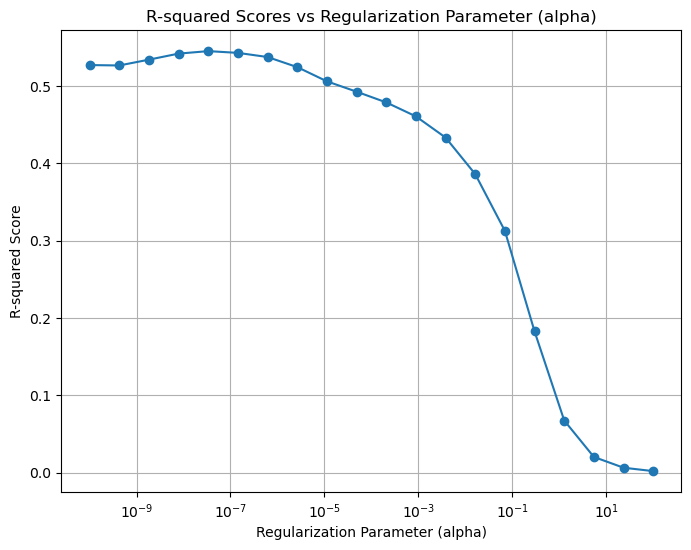

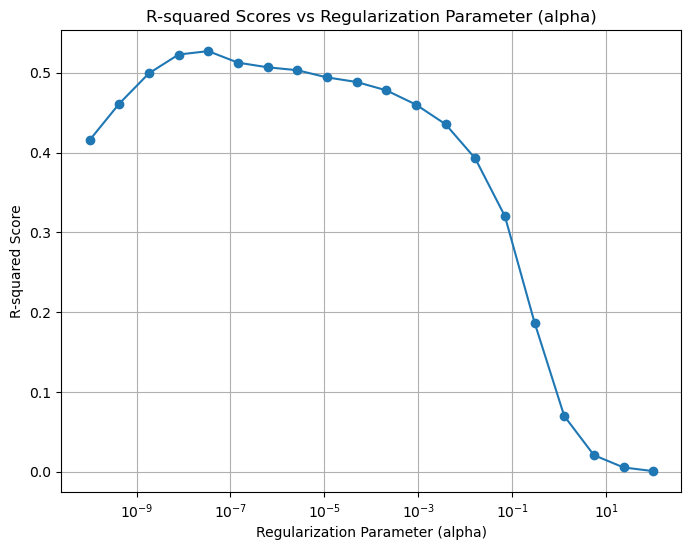

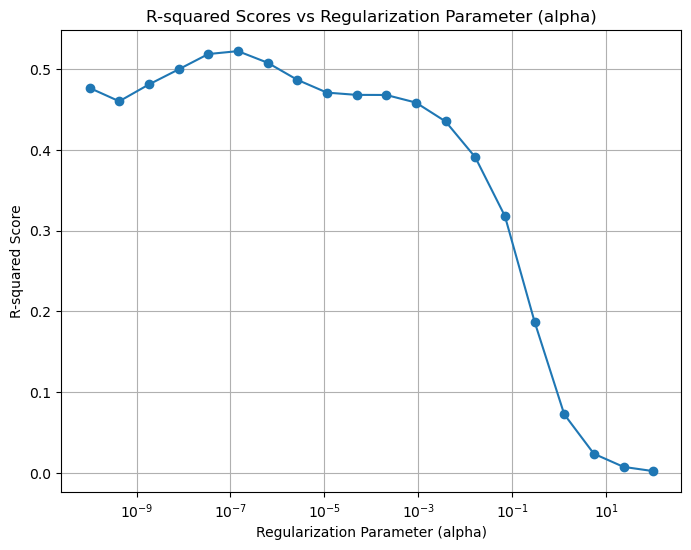

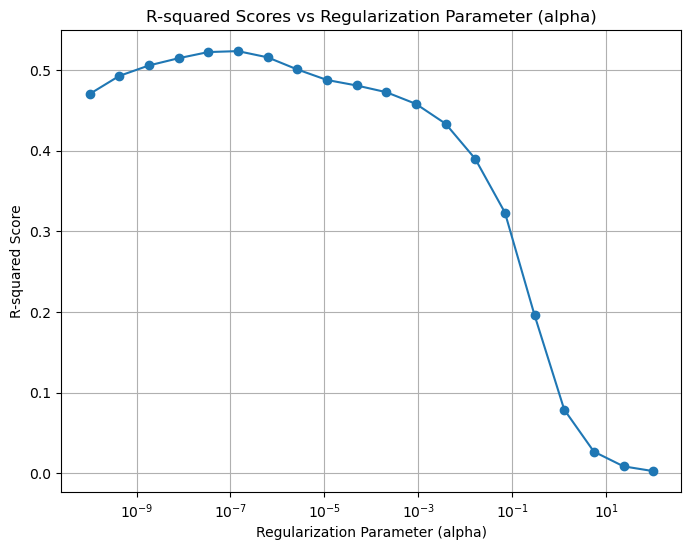

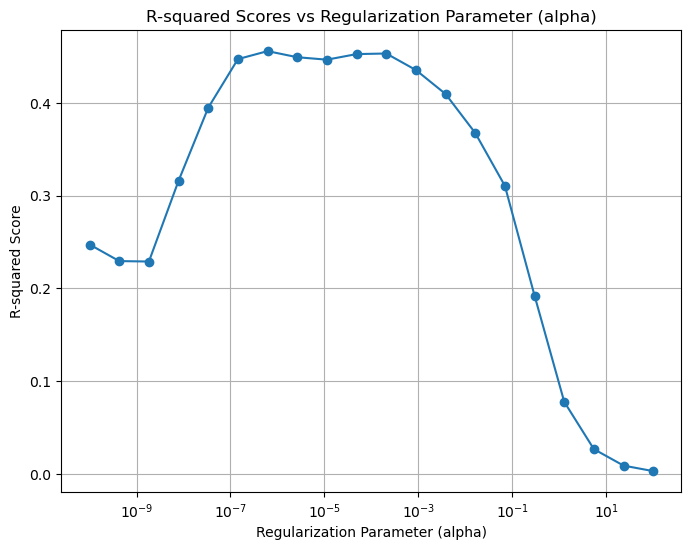

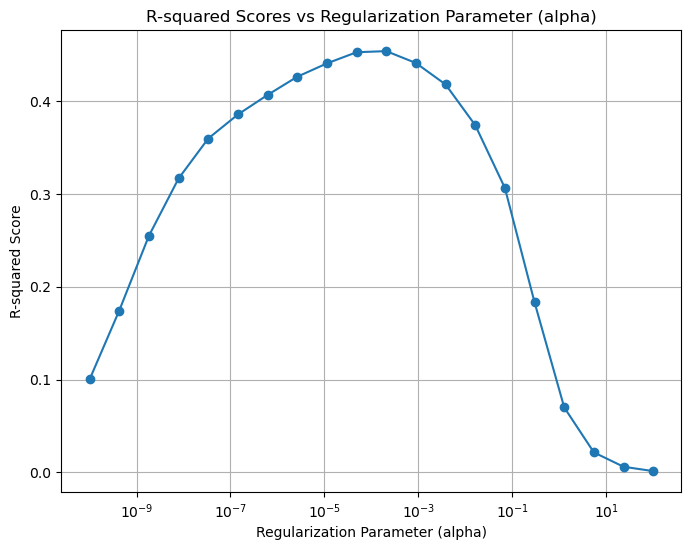

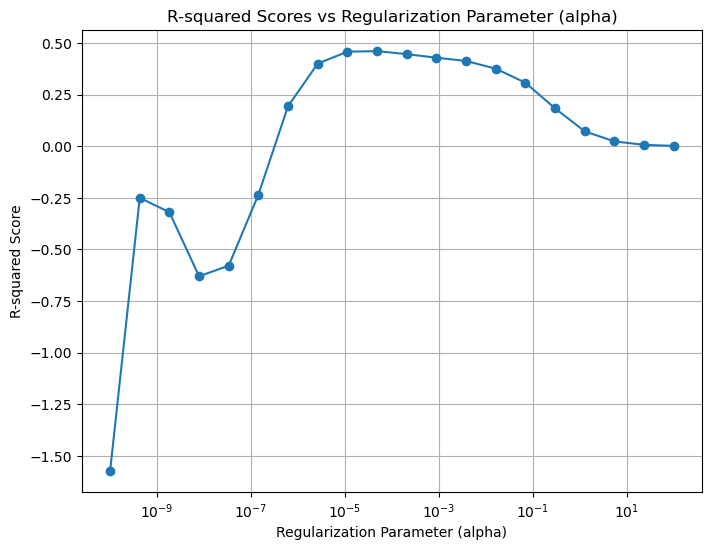

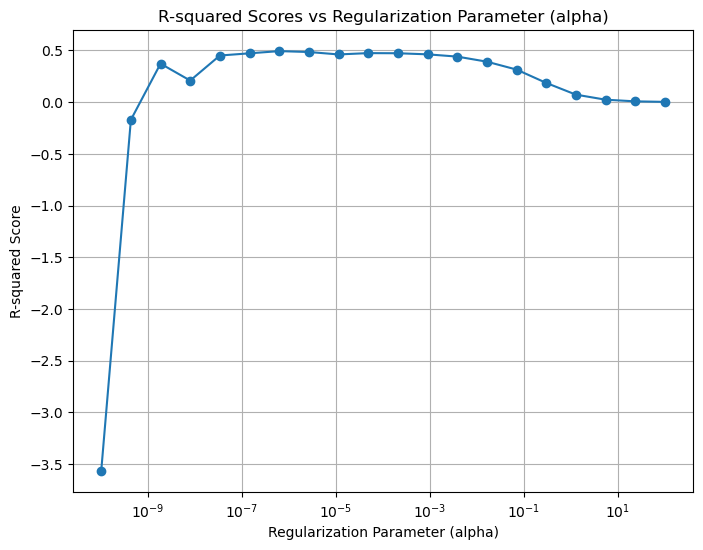

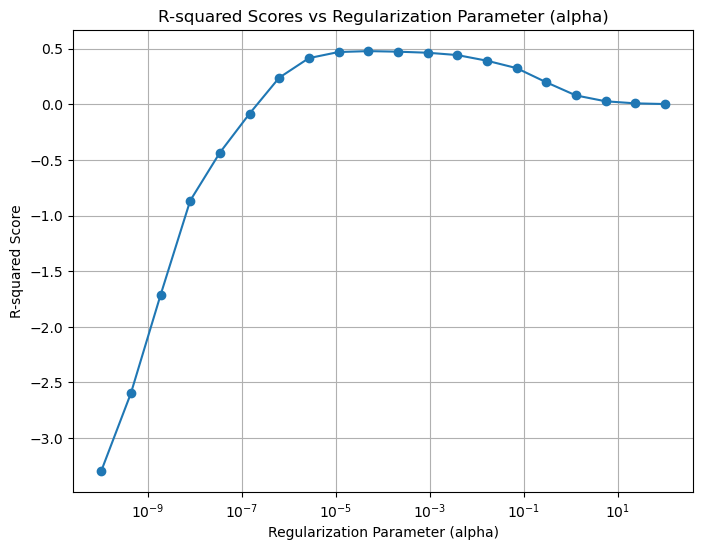

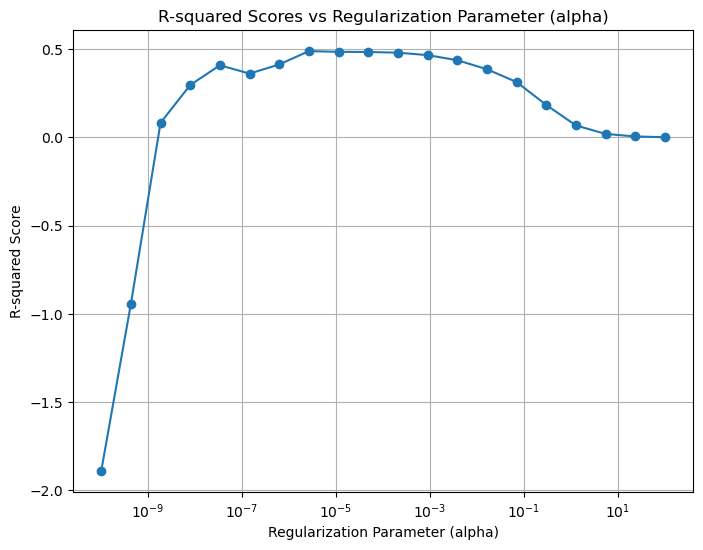

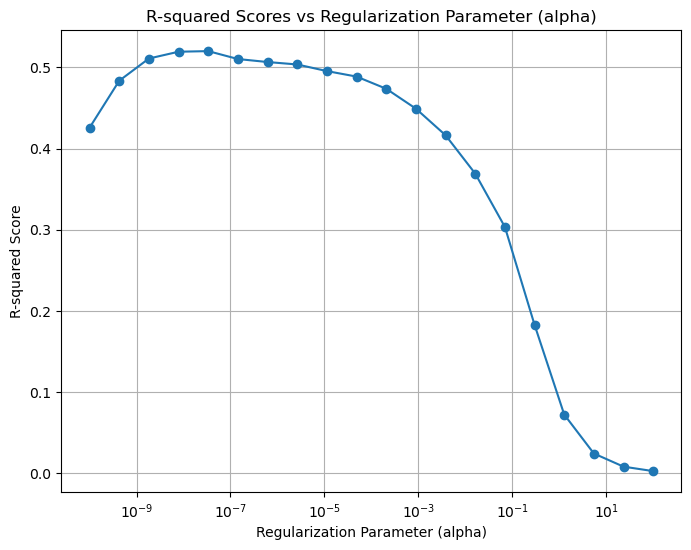

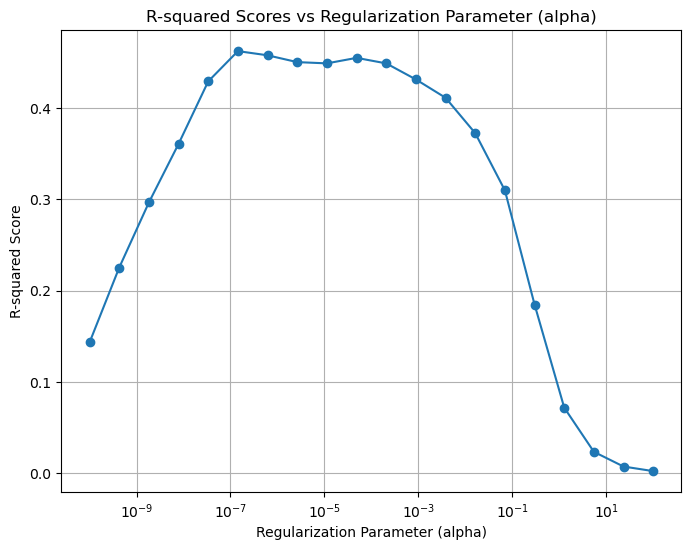

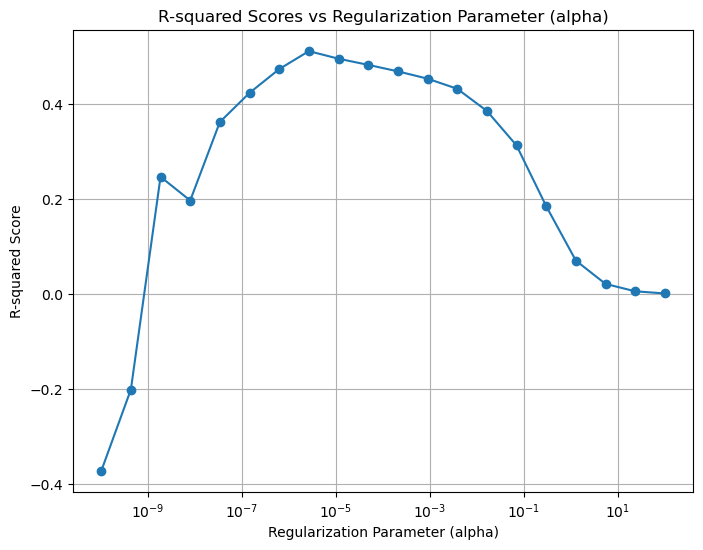

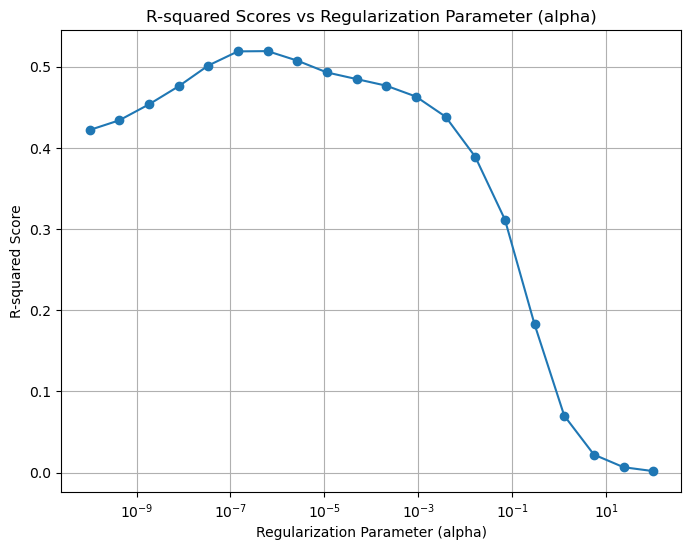

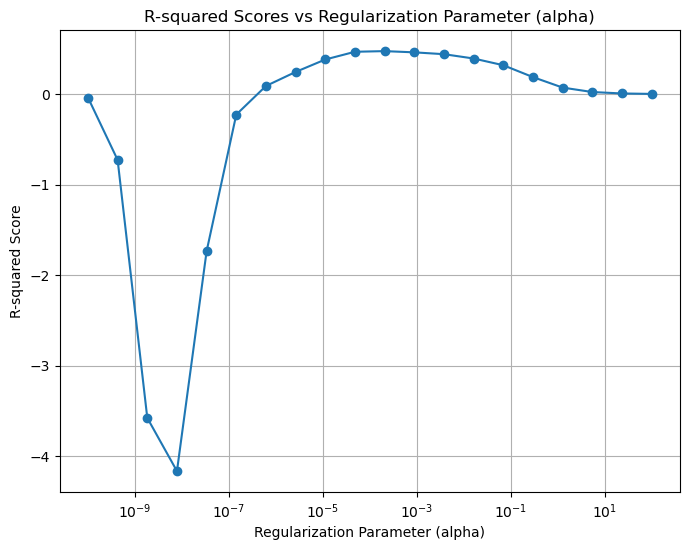

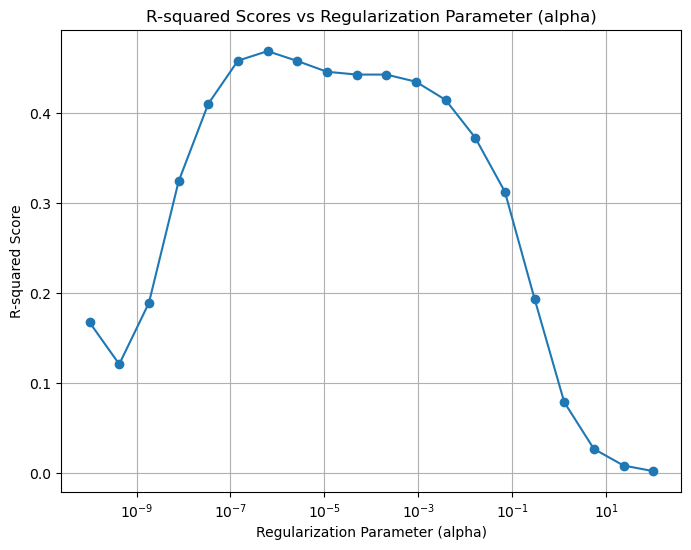

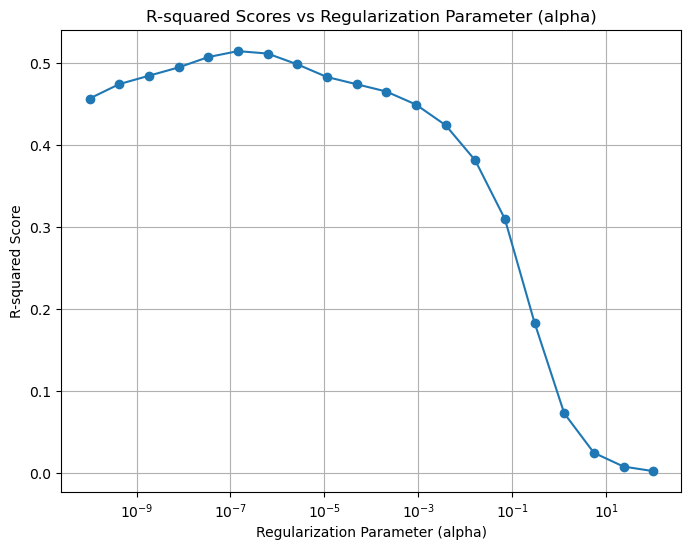

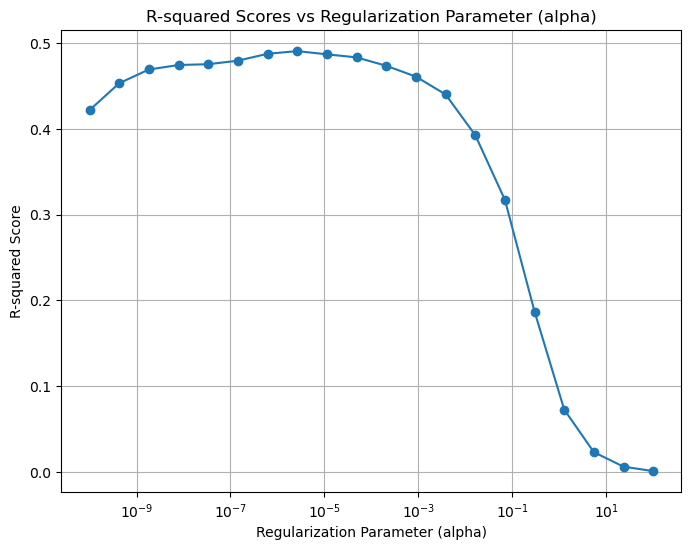

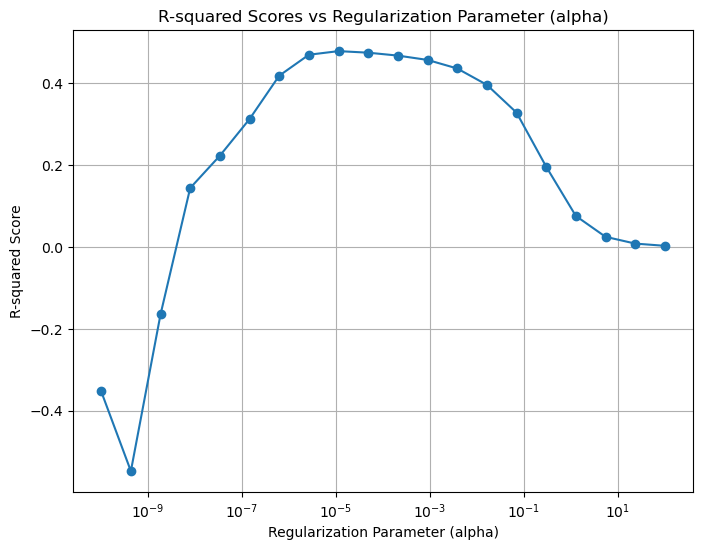

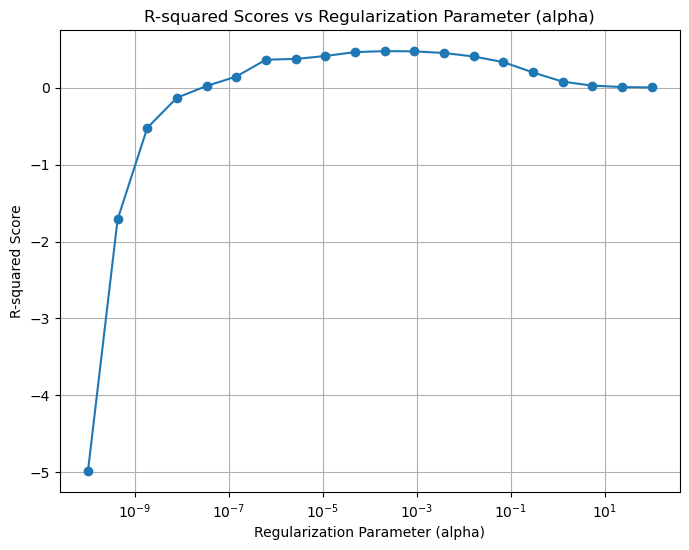

In [6]:
# Rerun 20 times

all_scores = []

regularization_params = np.geomspace(1e-10, 1e2, 20)


for i in range(20): 

    # Split the dataset into 80% training and 20% validation
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=None) # None generates a random seed

    scores = []

    for alpha in regularization_params:
        model = Pipeline([
            ("features", PolynomialFeatures(3)), # Calculates the design matrix for a third order polynomial
            ("normalization", Normalizer()), # Normalizes the features to a (0, 1) range. 
            ("model", Ridge(alpha=alpha)), # The regression model and regularization parameter value
        ])
        
        # Fit the model on the training data
        model.fit(X_train, y_train)
        
        # Evaluate the model on the validation data
        score = model.score(X_val, y_val) # r2 score on the validation data
        scores.append(score)
    
    all_scores.append(scores)

    # Plot the R-squared scores against regularization parameters
    plt.figure(figsize=(8, 6))
    plt.plot(regularization_params, scores, marker='o')
    plt.xscale('log')  # Logarithmic scale for x-axis
    plt.title('R-squared Scores vs Regularization Parameter (alpha)')
    plt.xlabel('Regularization Parameter (alpha)')
    plt.ylabel('R-squared Score')
    plt.grid(True)
    plt.show()

In [7]:
"""
Analysis of the Impact of Regularization Parameter (α) on Model Performance:

1. Small α (values close to 0.000000001 or 0.000001):
   - The R² scores are genreally low (negative), sometimes negative, indicating poor model performance.
   - At these levels, regularization is too weak, allowing the model to overfit the training data.
   - The model captures noise in the data, leading to poor generalization on the validation set.

2. Moderate α (values around 0.000001 to 0.00001):
   - The R² score improves significantly, peaking at approximately 0.5 near α = 0.000001 (10⁻⁶).
   - This range represents the optimal trade-off between bias and variance, as regularization is effective in controlling overfitting while retaining the model's ability to capture meaningful patterns in the data.
   - The model generalizes well to unseen data in this range.

3. Large α (values above 10.0):
   - The R² score starts to decline and approaches 0 as α becomes very large.
   - Excessive regularization forces the model coefficients to shrink too much, leading to underfitting.
   - The overly simplistic model fails to capture important patterns in the data, resulting in poor performance on the validation set.
"""


"\nAnalysis of the Impact of Regularization Parameter (α) on Model Performance:\n\n1. Small α (values close to 0.000000001 or 0.000001):\n   - The R² scores are genreally low (negative), sometimes negative, indicating poor model performance.\n   - At these levels, regularization is too weak, allowing the model to overfit the training data.\n   - The model captures noise in the data, leading to poor generalization on the validation set.\n\n2. Moderate α (values around 0.000001 to 0.00001):\n   - The R² score improves significantly, peaking at approximately 0.5 near α = 0.000001 (10⁻⁶).\n   - This range represents the optimal trade-off between bias and variance, as regularization is effective in controlling overfitting while retaining the model's ability to capture meaningful patterns in the data.\n   - The model generalizes well to unseen data in this range.\n\n3. Large α (values above 10.0):\n   - The R² score starts to decline and approaches 0 as α becomes very large.\n   - Excessive 


---
**Task 5 (easy): Evaluating models👩‍💻**
This task is about evaluating the effects of the regularisation parameters.
1. In the cell above, add a for-loop to rerun the cell 20 times and store the $R^2$ results from each iteration. The loop should repeat the 80-20 hold-out train-validation split each time as in [Task 1](#reflect). 
2. Calculate the mean and variance of the $R^2$ scores for each regularization value then run the cell below to plot the results. 
3. Based on the plots, which regularization parameter value gives the best results and why? Note down your observations and reflections in the cell below as it will be used in the next task.


---

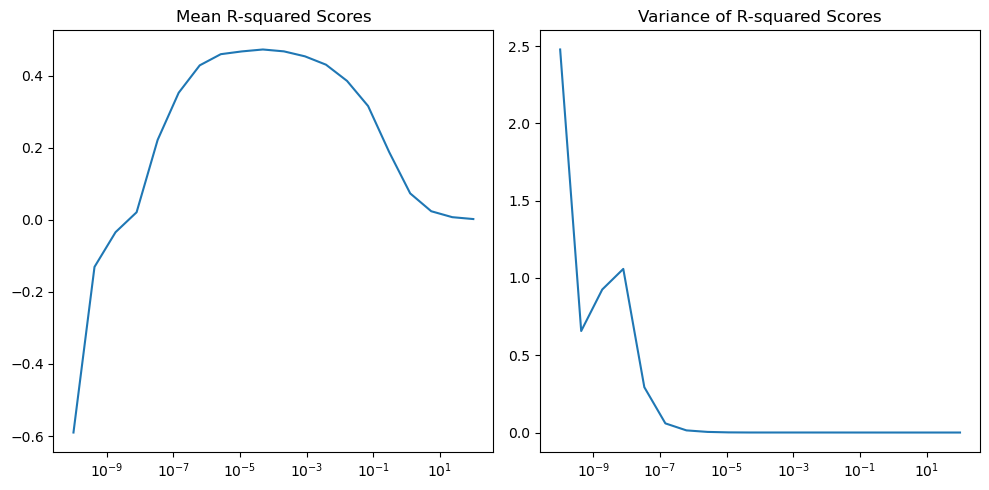

In [8]:
# Write your solution and reflections here
from statistics import variance

from numpy import var

all_scores = np.array(all_scores)
mean_scores = all_scores.mean(axis=0)
variance_scores = all_scores.var(axis=0)

# Plot the mean and variance R-squared scores
plt.figure(figsize=(10, 5))  # Set the figure size
plt.subplot(1, 2, 1)  # Subplot 1 for Mean R-squared
plt.plot(regularization_params, mean_scores, label='Mean R-squared')
plt.xscale('log')
plt.title('Mean R-squared Scores')

plt.subplot(1, 2, 2)  # Subplot 2 for Variance
plt.plot(regularization_params, variance_scores, label='Variance')
plt.xscale('log')
plt.title('Variance of R-squared Scores')

plt.tight_layout()  # Ensure proper spacing between subplots
plt.show()

In [9]:
"""
Best choice of penelty parameter:
The mean R2 scores increase, peaking around 
α=10^−4 or 10^−5, before gradually decreasing as α becomes larger.
This is the optimal range, where regularization balances bias and variance, leading to the best generalization.

Variance: 
The variance of R2 scores is highest at very low α values, indicating high variability in model performance.
As α increases, the variance decreases, meaning the model's performance becomes more consistent across different splits of the data.
Here models are more stable and able to generalize better to unseen data.
"""

"""
Too much regularization leads to more bias and less variance (overly simply) 
while too little regularization leads to more variance and less bias (overfitting).

Bias:
Bias refers to the error introduced by simplifying the assumptions made by the model to make it easier to learn from the data.
A model with high bias:
Assumes overly simplistic relationships between features and the target variable.
Fails to capture the complexity of the data, leading to underfitting.
Example: Using a linear model for data with a quadratic trend.

Variance:
Variance refers to the model's sensitivity to small fluctuations in the training data.
A model with high variance:
Learns the training data too well, including noise, leading to overfitting.
Performs poorly on unseen data because it fails to generalize.

The goal is to find the sweet spot where the model achieves:
Low bias: The model is complex enough to capture the true patterns in the data.
Low variance: The model avoids capturing noise and generalizes well to unseen data.
"""


"\nToo much regularization leads to more bias and less variance (overly simply) \nwhile too little regularization leads to more variance and less bias (overfitting).\n\nBias:\nBias refers to the error introduced by simplifying the assumptions made by the model to make it easier to learn from the data.\nA model with high bias:\nAssumes overly simplistic relationships between features and the target variable.\nFails to capture the complexity of the data, leading to underfitting.\nExample: Using a linear model for data with a quadratic trend.\n\nVariance:\nVariance refers to the model's sensitivity to small fluctuations in the training data.\nA model with high variance:\nLearns the training data too well, including noise, leading to overfitting.\nPerforms poorly on unseen data because it fails to generalize.\n\nThe goal is to find the sweet spot where the model achieves:\nLow bias: The model is complex enough to capture the true patterns in the data.\nLow variance: The model avoids captur

## Cross-validation

---
**Task 6 (medium): Cross validation👩‍💻**
This task investigates model generalization using k-fold cross validation.
1. Construct a new model, with the same setup as before by using the optimal regularization parameter found in the previous task. 
2. Train the model using k-fold cross validation. Set the number of folds to 2.
3. Vary the number of folds from 2 to 20 and calculate the mean and the standard deviation of the $R^2$ score for each fold. 
4. Plot the mean and the standard deviation of the $R^2$  scores as a function of the folds.


---

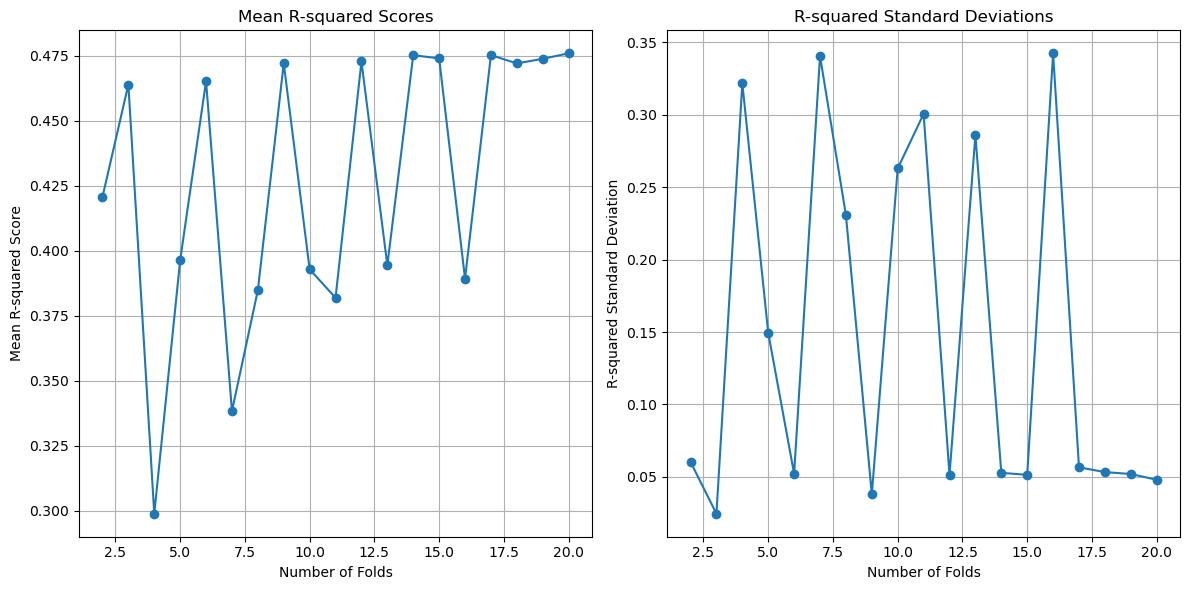

In [13]:
# Use the optimal regularization parameter from the previous task
optimal_alpha = 1e-5 

mean_r2_scores = []
std_r2_scores = []

# Vary the number of folds from 2 to 20
folds = range(2, 21)

for k in folds:
    model = Pipeline([
        ("features", PolynomialFeatures(3)),  # Third-order polynomial features
        ("normalization", Normalizer()),      
        ("model", Ridge(alpha=optimal_alpha)),  
    ])
    
    # Split the data into k folds
    kfold = KFold(n_splits=k, shuffle=True, random_state=42)  # Consistent splits
    
    # Perform cross-validation and extract test scores
    cv_results = cross_validate(model, X, y, cv=kfold, scoring='r2', return_train_score=False)
    r2_scores = cv_results['test_score']  # Extract the test scores
    
    # Store the mean and standard deviation of R² scores for this fold
    mean_r2_scores.append(np.mean(r2_scores))
    std_r2_scores.append(np.std(r2_scores))

# Plot Mean R² Scores and Standard Deviations side-by-side 
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot Mean R² Scores
axes[0].plot(folds, mean_r2_scores, marker='o')
axes[0].set_title('Mean R-squared Scores')
axes[0].set_xlabel('Number of Folds')
axes[0].set_ylabel('Mean R-squared Score')
axes[0].grid(True)

# Plot Standard Deviations of R² Scores
axes[1].plot(folds, std_r2_scores, marker='o')
axes[1].set_title('R-squared Standard Deviations')
axes[1].set_xlabel('Number of Folds')
axes[1].set_ylabel('R-squared Standard Deviation')
axes[1].grid(True)

# Adjust spacing and display the plots
plt.tight_layout()
plt.show()



---
**Task 7 (medium): Reflection on results💡**
1. Use the plotted mean and variance to argue about the model performance. 
2. List reasons for the variability in model performance? 
3. Compare the variability in model perfomance observed in the tutorial with the results of the current exercise.
4. Argue how the regularized model performs compared to the standard linear regression implemented in the tutorial. Print the model parameters and use them to argue for differences between the linear model and the regularized model.


---

In [11]:
"""
The number of folds in k-fold cross-validation impacts both variance and mean R² score:

1. **Low Number of Folds (e.g., k=2):**
   - At each time, 50% of the data is used for training and 50% for validation. 
   - High variance in R² scores due to inconsistent training-validation splits.
   - Lower mean R² score because training sets are smaller.
   - Faster computation due to fewer model evaluations.

2. **High Number of Folds (e.g., k=10 to k=20):**
   - Lower variance in R² scores due to more consistent splits.
   - Higher mean R² score as training sets are larger.
   - Slower computation because the model is evaluated more times.

**Trade-off:** 
Choosing an optimal number of folds (commonly k=5 or k=10) balances variance, mean R² score, and computational efficiency.
"""

"""
Reasons for Variability in Model Performance
Randomness in Training and Validation Splits:
Different splits can expose the model to slightly different subsets of the data, leading to variability in performance.

Small Dataset or High Fold Values:
For smaller datasets or higher k values, the validation sets become smaller, making the R2 scores more sensitive to outliers or noisy data points.

High-Variance Model:
The use of third-degree polynomial features increases model complexity, making it more sensitive to small changes in training data.

Noise in the Dataset:
Noise or outliers in the dataset can affect validation scores when they are included in training or validation sets.

Regularization Effects:
While regularization stabilizes the model, it may not completely remove sensitivity to changes in splits caused by small datasets or high model complexity.
"""

"""
In the current exercise, regularization (Ridge regression) reduces variability in performance by penalizing large model coefficients and controlling overfitting. However, fluctuations still exist due to data and split randomness.
Performance: Without regularization, the model is more likely to overfit the training data, especially with high-degree polynomial features.
Coefficients: The lack of penalty allows coefficients to grow large, capturing noise in the data.
Regularized models (Ridge regression) perform better in terms of generalization and stability, especially when working with polynomial features.
Regularization reduces variability in model performance by controlling overfitting.
"""

"""
This one has better R2 scores than the non reqularized 3 polynomial model. Even for the low scores are better
And also less variance in the scores.
Compared to non-regularized models, regularized models have smaller coefficients, which are more robust to noise and fluctuations in the dataset.
"""

'\nThis one has better R2 scores than the non reqularized 3 polynomial model. Even for the low scores are better\nAnd also less variance in the scores.\nCompared to non-regularized models, regularized models have smaller coefficients, which are more robust to noise and fluctuations in the dataset.\n'

In [14]:
# Train a Linear Regression model without regularization
linear_model = Pipeline([
    ("features", PolynomialFeatures(3)),
    ("normalization", Normalizer()),
    ("model", LinearRegression()),
])
linear_model.fit(X, y)

# Train a Ridge Regression model with regularization
ridge_model = Pipeline([
    ("features", PolynomialFeatures(3)),
    ("normalization", Normalizer()),
    ("model", Ridge(alpha=1e-5)),
])
ridge_model.fit(X, y)

# Extract coefficients from the trained models
linear_coefficients = linear_model.named_steps['model'].coef_
ridge_coefficients = ridge_model.named_steps['model'].coef_

# Print the first 40 Ridge Regression coefficients
print("First 40 Ridge Model Coefficients:")
print(ridge_coefficients[:40])

# Print the first 40 Linear Regression coefficients
print("\nFirst 40 Linear Model Coefficients:")
print(linear_coefficients[:40])

First 40 Ridge Model Coefficients:
[-9.09153232e-02 -2.17134418e-01 -1.78495779e+00 -3.14226807e-01
 -6.71896651e-02 -1.35859128e+01 -9.97458116e-02 -2.01340085e+00
  7.16505322e+00  2.04753932e+00 -1.34819525e+00 -2.25382593e+00
  2.34772513e+00 -3.82223665e+01 -6.90182658e-01 -3.86843855e+00
  1.20580061e+01 -3.45712911e+01 -1.87269596e+00 -1.74234195e+00
 -2.11242148e+02 -1.80969156e+00 -3.06242103e+01  1.06356471e+02
  1.28443375e+00  1.15527584e+00 -3.96353839e+01  1.14136370e+00
 -4.93691828e+00  1.87075894e+01  1.22648109e+00 -1.57107859e+01
 -9.93919066e-01  4.84785779e-02  3.35219734e+00 -3.92776359e+03
 -1.27830493e+01 -2.33624263e+02  8.08540602e+02 -2.25218330e+00]

First 40 Linear Model Coefficients:
[-9.90117339e+10 -3.63582078e+09 -4.77358914e+08  4.44022213e+09
 -2.62639965e+10  7.31923966e+07 -6.08346648e+09  5.66591793e+08
 -2.65486627e+09 -1.03919952e+07 -1.71559380e+06  2.00702279e+06
 -5.30116949e+07 -1.08172230e+06  5.47762012e+07 -6.96492910e+07
 -8.21969482e+07 